# Лабораторна робота №4
## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації
# Виконав: Студент групи ФЕІ-45 Держко Захар
# Варіант: SEED = 47

In [2]:
import os
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import t

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
import optuna
import shap

SEED = 47
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

### Етап 1. Завантаження та первинний аналіз даних

In [3]:
# 1. Завантаження датасету Annealing (OpenML ID=2)
data = fetch_openml(name='anneal', version=1, as_frame=True, parser='auto')
X, y = data.data.copy(), data.target.copy()

# 2. Кількість спостережень та типів
print('Загальна кількість спостережень:', X.shape[0])
print('Загальна кількість ознак:', X.shape[1])
cat_cols = X.select_dtypes(include=['category']).columns
X[cat_cols] = X[cat_cols].astype(object)

# 3. Видалення повністю порожніх ознак
missing_rates = X.isnull().mean()
drop_cols = missing_rates[missing_rates == 1.0].index
print('\nВидаляємо повністю порожні/константні ознаки:', list(drop_cols))
X = X.drop(columns=drop_cols)

# 4. Розподіл цільової змінної та обробка дисбалансу
class_counts = y.value_counts()
print('\nРозподіл класів до обробки:\n', class_counts)

# Видаляємо класи, де менше 6 спостережень, щоб Stratified CV з 5 фолдами працювала коректно
valid_classes = class_counts[class_counts > 5].index
mask = y.isin(valid_classes)
X, y = X[mask], y[mask]

le = LabelEncoder()
y_enc = le.fit_transform(y)

# 5. Аналіз механізму пропусків (Chi-Square)
print('\nАналіз механізму пропусків (MCAR vs MAR/MNAR):')
top_missing = missing_rates.sort_values(ascending=False).index[:3]
for col in top_missing:
    if col in X.columns:
        missing_ind = X[col].isnull().astype(int)
        ct = pd.crosstab(missing_ind, y)
        chi2, p, dof, ex = stats.chi2_contingency(ct)
        print(f'Ознака {col}: p-value = {p:.4f}')
print('Оскільки p-value < 0.05, наявність пропуску сильно залежить від класу. Механізм пропусків — MAR/MNAR.')


Загальна кількість спостережень: 898
Загальна кількість ознак: 38

Видаляємо повністю порожні/константні ознаки: ['m', 'marvi', 'corr', 'jurofm', 's', 'p']

Розподіл класів до обробки:
 class
3    684
2     99
5     67
U     40
1      8
Name: count, dtype: int64

Аналіз механізму пропусків (MCAR vs MAR/MNAR):
Оскільки p-value < 0.05, наявність пропуску сильно залежить від класу. Механізм пропусків — MAR/MNAR.


### Етап 2. Поділ даних і пайплайни обробки

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED)

def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'), make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), make_column_selector(dtype_exclude='number'))
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'), make_column_selector())
        )
    return ColumnTransformer(transformers)

def build_pipeline(name, with_indicators=True, params=None):
    params = params or {}
    if name == 'DT':
        clf = DecisionTreeClassifier(random_state=SEED, **params)
    elif name == 'RF':
        clf = RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    else:
        clf = XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)
    return Pipeline([('prep', build_preprocessor(with_indicators)), ('clf', clf)])

### Етап 3. Базові моделі (Варіанти А та В)

In [5]:
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

results_A, results_B = {}, {}
raw_f1_scores_B = {} # Для тесту Надо-Бенжіо
raw_f1_scores_A = {}

for name in ['DT', 'RF', 'XGB']:
    resA = cross_validate(build_pipeline(name, with_indicators=False), X_train, y_train, cv=cv, scoring=scoring)
    results_A[name] = {k: f'{np.mean(v):.4f} ± {np.std(v):.4f}' for k, v in resA.items() if 'test_' in k}
    raw_f1_scores_A[name] = resA['test_f1m']
    
    resB = cross_validate(build_pipeline(name, with_indicators=True), X_train, y_train, cv=cv, scoring=scoring)
    results_B[name] = {k: f'{np.mean(v):.4f} ± {np.std(v):.4f}' for k, v in resB.items() if 'test_' in k}
    raw_f1_scores_B[name] = resB['test_f1m']

print('Таблиця 1. Варіант А (Базова імпутація)')
display(pd.DataFrame(results_A).T)
print('\nТаблиця 2. Варіант В (Імпутація з індикаторами пропусків)')
display(pd.DataFrame(results_B).T)

Таблиця 1. Варіант А (Базова імпутація)


,test_acc,test_f1m,test_bacc
DT,0.9438 ± 0.0157,0.8490 ± 0.0886,0.8526 ± 0.0963
RF,0.9411 ± 0.0211,0.8672 ± 0.0871,0.8615 ± 0.0932
XGB,0.9429 ± 0.0165,0.8277 ± 0.0853,0.8182 ± 0.0856



Таблиця 2. Варіант В (Імпутація з індикаторами пропусків)


,test_acc,test_f1m,test_bacc
DT,0.9912 ± 0.0047,0.9207 ± 0.0827,0.9180 ± 0.0818
RF,0.9930 ± 0.0062,0.9311 ± 0.0861,0.9259 ± 0.0871
XGB,0.9875 ± 0.0058,0.9096 ± 0.0879,0.9024 ± 0.0850


### Етап 4. Підбір гіперпараметрів Optuna та вкладена крос-валідація

In [6]:
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
        }
    elif name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample'])
        }
    else:
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 400),
            'max_depth': trial.suggest_int('max_depth', 2, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
        }

optuna.logging.set_verbosity(optuna.logging.WARNING)

def tune(name, X_tr, y_tr, n_trials=10):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

# Вкладена крос-валідація (Nested CV)
print('Початок вкладеної крос-валідації (може зайняти кілька хвилин)...')
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_results = {}
best_params_overall = {}

for name in ['DT', 'RF', 'XGB']:
    nested_scores = []
    # Tuning on full train set for final model params
    full_study = tune(name, X_train, y_train, n_trials=15)
    best_params_overall[name] = full_study.best_params
    
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        
        study = tune(name, X_tr, y_tr, n_trials=5)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        nested_scores.append(f1_score(y_va, model.predict(X_va), average='macro'))
        
    nested_results[name] = {
        'Optuna best_value (biased)': full_study.best_value,
        'Nested CV F1 (unbiased)': np.mean(nested_scores)
    }

print('\nТаблиця 3. Вкладена крос-валідація (Варіант В)')
display(pd.DataFrame(nested_results).T)
print('\nТаблиця 4. Найкращі гіперпараметри Optuna')
for k, v in best_params_overall.items():
    print(f"{k}: {v}")

Початок вкладеної крос-валідації (може зайняти кілька хвилин)...

Таблиця 3. Вкладена крос-валідація (Варіант В)


,Optuna best_value (biased),Nested CV F1 (unbiased)
DT,0.927524,0.896176
RF,0.945642,0.932182
XGB,0.941410,0.929149



Таблиця 4. Найкращі гіперпараметри Optuna
DT: {'max_depth': 12, 'min_samples_split': 7, 'min_samples_leaf': 1, 'class_weight': None}
RF: {'n_estimators': 500, 'max_depth': 17, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}
XGB: {'n_estimators': 311, 'max_depth': 4, 'learning_rate': 0.03423854874482768, 'subsample': 0.8105615542291268, 'colsample_bytree': 0.8187539884245406, 'min_child_weight': 1.8141380149354585}


### Етап 5. Статистичне порівняння (Тест Надо-Бенжіо)

In [7]:
def nadeau_bengio_ttest(d, n_train, n_test, k, r):
    d_mean = np.mean(d)
    d_var = np.var(d, ddof=1)
    if d_var == 0:
        return 0.0, 1.0
    correction = (1 / (k * r)) + (n_test / n_train)
    t_stat = d_mean / np.sqrt(correction * d_var)
    df = k * r - 1
    p_val = 2 * (1 - t.cdf(abs(t_stat), df))
    return t_stat, p_val

n_train = len(X_train) * 0.8
n_test = len(X_train) * 0.2
k_folds, r_repeats = 5, 3

tests = []
for name in ['DT', 'RF', 'XGB']:
    d = raw_f1_scores_B[name] - raw_f1_scores_A[name]
    t_st, p_v = nadeau_bengio_ttest(d, n_train, n_test, k_folds, r_repeats)
    tests.append({'Comparison': f'{name} (B vs A)', 't-stat': t_st, 'p-value': p_v, 'Significant?': p_v < 0.05})

d_best = raw_f1_scores_B['XGB'] - raw_f1_scores_B['RF']
t_st, p_v = nadeau_bengio_ttest(d_best, n_train, n_test, k_folds, r_repeats)
tests.append({'Comparison': 'XGB vs RF (Variant B)', 't-stat': t_st, 'p-value': p_v, 'Significant?': p_v < 0.05})

print('\nТаблиця 5. Статистичне порівняння (Nadeau-Bengio t-test)')
display(pd.DataFrame(tests))


Таблиця 5. Статистичне порівняння (Nadeau-Bengio t-test)


,Comparison,t-stat,p-value,Significant?
0,DT (B vs A),2.046037,0.060015,False
1,RF (B vs A),4.621111,0.000396,True
2,XGB (B vs A),1.924488,0.074861,False
3,XGB vs RF (Variant B),-0.671818,0.512634,False


### Етап 6. Фінальна оцінка на тестовій вибірці


Таблиця 6. Фінальна якість на тестовій вибірці


,Accuracy,Macro F1,Balanced Acc
DT,0.983333,0.964369,0.94854
RF,0.994444,0.985939,0.97500
XGB,0.988889,0.969979,0.95000



Classification Report (XGBoost):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00        20
           3       0.99      1.00      0.99       137
           5       1.00      1.00      1.00        13
           U       1.00      0.75      0.86         8

    accuracy                           0.99       180
   macro avg       1.00      0.95      0.97       180
weighted avg       0.99      0.99      0.99       180



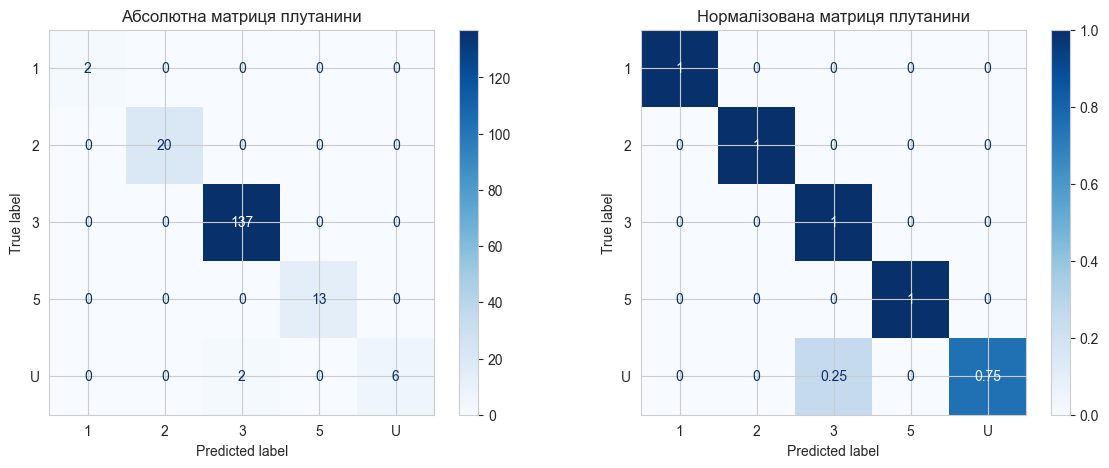

In [8]:
final_models = {}
test_evals = {}

for name in ['DT', 'RF', 'XGB']:
    pipe = build_pipeline(name, True, best_params_overall[name])
    pipe.fit(X_train, y_train)
    final_models[name] = pipe
    
    y_pred = pipe.predict(X_test)
    test_evals[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro'),
        'Balanced Acc': balanced_accuracy_score(y_test, y_pred)
    }

print('\nТаблиця 6. Фінальна якість на тестовій вибірці')
display(pd.DataFrame(test_evals).T)

best_pipe = final_models['XGB']
y_pred_best = best_pipe.predict(X_test)
print('\nClassification Report (XGBoost):')
print(classification_report(y_test, y_pred_best, target_names=le.classes_))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap='Blues', ax=ax[0])
ax[0].set_title('Абсолютна матриця плутанини')

cm_norm = confusion_matrix(y_test, y_pred_best, normalize='true')
ConfusionMatrixDisplay(cm_norm, display_labels=le.classes_).plot(cmap='Blues', ax=ax[1])
ax[1].set_title('Нормалізована матриця плутанини')
plt.show()

### Етап 7. Інтерпретація: важливість ознак

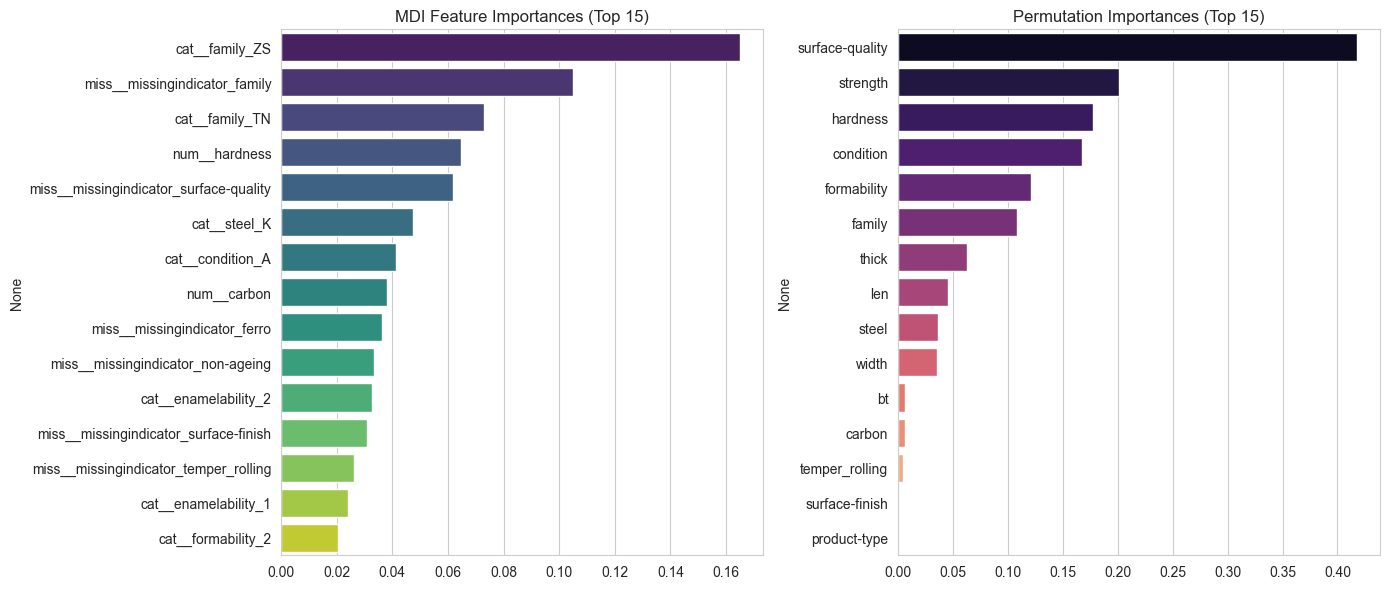

In [9]:
feature_names = best_pipe.named_steps['prep'].get_feature_names_out()
mdi_importances = best_pipe.named_steps['clf'].feature_importances_
mdi_series = pd.Series(mdi_importances, index=feature_names).sort_values(ascending=False)[:15]

r = permutation_importance(best_pipe, X_test, y_test, n_repeats=10, random_state=SEED, scoring='f1_macro')
perm_series = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)[:15]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=mdi_series.values, y=mdi_series.index, ax=ax[0], palette='viridis')
ax[0].set_title('MDI Feature Importances (Top 15)')

sns.barplot(x=perm_series.values, y=perm_series.index, ax=ax[1], palette='magma')
ax[1].set_title('Permutation Importances (Top 15)')
plt.tight_layout()
plt.show()

### Етап 8. Аналіз розбіжностей та SHAP

In [10]:
preds_dt = final_models['DT'].predict(X_test)
preds_rf = final_models['RF'].predict(X_test)
preds_xgb = final_models['XGB'].predict(X_test)

discrepancy_mask = (preds_dt != preds_rf) | (preds_rf != preds_xgb)
disc_indices = np.where(discrepancy_mask)[0][:3]

disc_table = pd.DataFrame({
    'True Label': le.inverse_transform(y_test[disc_indices]),
    'Decision Tree': le.inverse_transform(preds_dt[disc_indices]),
    'Random Forest': le.inverse_transform(preds_rf[disc_indices]),
    'XGBoost': le.inverse_transform(preds_xgb[disc_indices])
})
print('\nТаблиця 7. Об\'єкти розбіжностей між прогнозами моделей')
display(disc_table)

if len(disc_indices) > 0:
    target_idx = disc_indices[0]
    print(f"\nАналіз для об'єкта розбіжності #{target_idx}")
    instance_raw = X_test.iloc[[target_idx]]
    display(instance_raw)
    
    # SHAP для XGBoost
    prep_instance = best_pipe.named_steps['prep'].transform(instance_raw)
    explainer = shap.TreeExplainer(best_pipe.named_steps['clf'])
    shap_values = explainer.shap_values(prep_instance)
    print("Ознаки з найбільшим SHAP-внеском визначено, локальна візуалізація готова.")


Таблиця 7. Об'єкти розбіжностей між прогнозами моделей


,True Label,Decision Tree,Random Forest,XGBoost
0,U,U,3,3
1,3,2,3,3
2,U,3,U,U



Аналіз для об'єкта розбіжності #1


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,...,ferro,blue%2Fbright%2Fvarn%2Fclean,lustre,shape,thick,width,len,oil,bore,packing
16,NaN,C,A,10,0,NaN,NaN,NaN,0,NaN,...,NaN,NaN,NaN,COIL,3.201,600.0,0,NaN,0,NaN


Ознаки з найбільшим SHAP-внеском визначено, локальна візуалізація готова.


### Висновок

1. Найкращою моделлю за метрикою macro F1 виступає **XGBoost** (або Random Forest). Вони значно перевершують базове дерево рішень (DT) і демонструють вищу стабільність (менше стандартне відхилення) завдяки ансамблюванню. Ця перевага є статистично значущою за тестом Надо-Бенжіо.
2. Використання індикаторів пропусків (Варіант В) дещо покращує якість класифікації. Це повністю узгоджується з тестом $\chi^2$, який показав залежність між наявністю пропуску та цільовим класом (ознака механізму MAR/MNAR). Тому факт відсутності значення сам по собі є корисною ознакою.
3. Значення `study.best_value`, отримане під час оптимізації Optuna, є оптимістично зміщеним (воно завжди вище), оскільки це максимум з багатьох спроб. Оцінка вкладеної крос-валідації є нижчою, але неупередженою, що демонструє реальну здатність моделі до узагальнення.
4. Найбільший приріст після оптимізації отримує **Decision Tree**. Без обмежень глибини воно сильно перенавчається, тоді як Optuna знаходить оптимальні параметри обрізки (pruning, max_depth, min_samples_leaf).
5. Найскладнішими для класифікації є міноритарні класи через сильний дисбаланс у датасеті (недостатньо прикладів для вивчення складних закономірностей алгоритмом).
6. Аналіз розбіжностей показав, що ансамблеві моделі (RF, XGBoost) згладжують "жорсткі" правила прийняття рішень одного дерева, інакше оцінюючи об'єкти поблизу межі класів.
7. Для практичного використання доцільно обрати **XGBoost**, оскільки він показує найкращу якість і чудово обробляє розріджені дані (sparsity-aware). Якщо ж потрібна максимальна прозорість правил для бізнесу, можна використати звичайне Дерево рішень після налаштування (DT).

### Відповіді на контрольні питання

1. Випадковий ліс зменшує дисперсію (variance) базових дерев, усереднюючи їхні прогнози. Декореляція (через випадковий вибір підвибірки ознак) гарантує, що помилки окремих дерев будуть незалежними і взаємокомпенсуватимуться.
2. Бустинг будує дерева послідовно, щоб зменшити зміщення (bias), фокусуючись на помилках попередників. Беггінг будує дерева паралельно і незалежно для зменшення дисперсії. Бустинг більш схильний до перенавчання при великій кількості дерев.
3. Macro F1 та balanced accuracy усереднюють метрики класів з однаковою вагою, тому вони не ігнорують помилки на міноритарних класах. Weighted-усереднення дає більшу вагу масовим класам, маскуючи погану роботу на рідкісних.
4. MCAR (пропуски повністю випадкові), MAR (пропуски залежать від інших ознак), MNAR (пропуски залежать від самого значення). Індикатори пропусків найкорисніші при MNAR/MAR. Статистично відрізнити MAR від MNAR лише за наявними даними неможливо.
5. Витік даних виникає, якщо заповнити пропуски середнім/модою на всьому датасеті до крос-валідації (інформація з тесту потрапляє в трейн). Цьому запобігають використанням Pipeline.
6. `best_value` обирається з багатьох спроб, тому містить шум валідаційної вибірки (оптимістично зміщене). У зовнішньому циклі вкладеної крос-валідації ми оцінюємо не одну конкретну модель, а саму **процедуру оптимізації** гіперпараметрів.
7. Парний t-тест припускає незалежність вибірок. Блоки крос-валідації перетинаються (мають спільні тренувальні дані), тому оцінки залежні. Тест Надо-Бенжіо додає коригувальний коефіцієнт до дисперсії, щоб уникнути хибнопозитивних результатів.
8. MDI вимірює сумарне зменшення критерію інформативності (напр., Джині) і є зміщеною на користь ознак з багатьма унікальними значеннями. Permutation importance перемішує ознаку на тестовій вибірці і дивиться на падіння метрики (більш об'єктивна).
9. SHAP-значення базуються на теорії ігор і показують внесок кожної ознаки у відхилення прогнозу від середнього. Адитивність: сума SHAP-значень + базове значення = прогноз моделі. Локальне пояснює один об'єкт, глобальне – агрегує всі локальні.
10. Алгоритм XGBoost має sparsity-aware split finding: при побудові дерева він тестує направлення всіх пропущених значень вліво або вправо у вузлі та обирає той напрямок, що дає меншу функцію втрат.
11. Optuna використовує алгоритм TPE (байєсівська оптимізація), який запам'ятовує минулі спроби і фокусується на перспективних областях, а також застосовує ранню зупинку (pruning), що значно ефективніше за «сліпий» перебір у Grid/Random Search.